# Assignment 03: Neural Networks

**Index No:** 230186E  
**Name:** Fernando W. H. D.  
**GitHub:** https://github.com/himashafdo/EN3160-A03.git

## Question 01

Epoch 1 / 10 , Loss : 1.8999559814929963 
Epoch 2 / 10 , Loss : 1.7177047282457352 
Epoch 3 / 10 , Loss : 1.651229669213295 
Epoch 4 / 10 , Loss : 1.6038031356334685 
Epoch 5 / 10 , Loss : 1.564653952240944 
Epoch 6 / 10 , Loss : 1.5299329755306244 
Epoch 7 / 10 , Loss : 1.5000821765661239 
Epoch 8 / 10 , Loss : 1.4729240270853043 
Epoch 9 / 10 , Loss : 1.4487080460786819 
Epoch 10 / 10 , Loss : 1.4272706052064896 


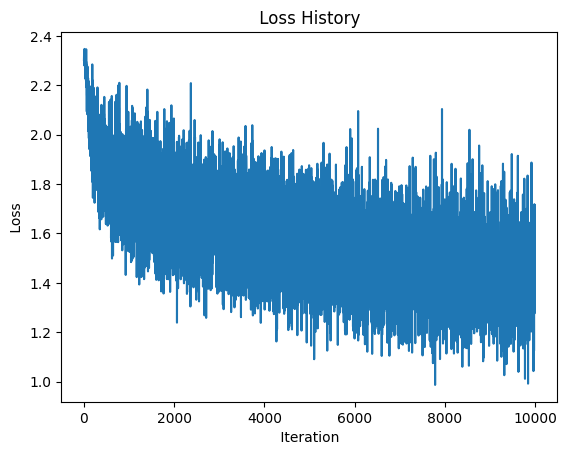

 Training accuracy : 51.80%
Test accuracy: 47.53%


In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Dataloading
transform = transforms.Compose ([transforms.ToTensor() ,transforms.Normalize ((0.5,0.5,0.5) , (0.5,0.5,0.5))])

batch_size = 50

torch.manual_seed(0) # I added this to make the discussion results consistant every time I run it

trainset = torchvision.datasets.CIFAR10( root= './data' , train=True ,download=True , transform=transform )
trainloader = torch.utils.data.DataLoader( trainset , batch_size=batch_size ,shuffle=True , num_workers=2)
testset = torchvision.datasets.CIFAR10( root= './data' , train=False ,download=True , transform=transform )
testloader = torch.utils.data.DataLoader( testset , batch_size=batch_size ,shuffle=False , num_workers=2)

classes = ( ' plane ' , ' car ' , ' bird ' , ' cat ' ,' deer ' , ' dog ' , ' frog ' , ' horse ' , ' ship ' , ' truck ')


# 2. Define Network Parameters
Din = 3*32*32  # Input size(flattened CIFAR−10 image size)

K = 10  # Output size (number of classes in CIFAR−10)
std = 1e-2 #changed this ones since 1e-5 makes the weights almost zero================
H = 100 #hidden layer nodes

# Initialize weights and biases, I changed this according to accomodate the middle layer
w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10 #10 epochs
lr = 1e-1 #with cross entrpoy loss function gradinet is much smaller weights wont change fro prev lr ============
lr_decay = 0.9 # Learning rate decay
reg = 0 # Regularization
loss_history = []

#helper functions I defined 
def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))

def softmax(logits):
    logits = logits - logits.max(dim=1, keepdim=True).values
    e = torch.exp(logits)
    return e / e.sum(dim=1, keepdim=True)

# 3. Training Loop
for t in range( iterations ):
    running_loss = 0.0
    for i , data in enumerate( trainloader, 0 ):

        # Get inputs and labe l s
        inputs, labels = data
        Ntr = inputs . shape [0]  # Batch size

        x_train = inputs.view ( Ntr , -1) # Flatten input to ( Ntr , Din )
        y_train_onehot = nn.functional.one_hot ( labels , K) . float ( ) # Convert labels to one−hot
        
        # Forward pass
        #y_pred = x_train.mm(w) + b # Output layer activation

        h = sigmoid(x_train.mm(w1) + b1) #middle layer with sigmoid activiaiton
        logits = h.mm(w2) + b2
        p = softmax(logits)


        # Loss calculation (Mean Squared Error with regularization )
        #loss = (1 / Ntr ) * torch.sum( ( y_pred - y_train_onehot ) ** 2) + reg * torch.sum(w ** 2)
        loss = -(1/Ntr) * torch.sum(y_train_onehot * torch.log(p + 1e-12)) #cross rntropy loss function imlemented
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        # dy_pred = (2.0 / Ntr ) * (y_pred - y_train_onehot)
        # dw = x_train.t ( ) .mm( dy_pred ) + reg * w
        # db = dy_pred.sum(dim=0)

        dlogits = (p - y_train_onehot) / Ntr
        dw2 = h.t().mm(dlogits)
        db2 = dlogits.sum(dim=0)
        dz1 = dlogits.mm(w2.t()) * h * (1 - h)
        dw1 = x_train.t().mm(dz1)
        db1 = dz1.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t%1 == 0:
        print (f"Epoch { t + 1 } / { iterations } , Loss : { running_loss / len ( trainloader) } " )


    # Learning rate decay
    lr *= lr_decay


# 4. Plotting the Loss History
plt.plot (loss_history)
plt.title ( " Loss History " )
plt.xlabel ( " Iteration " )
plt.ylabel ( " Loss " )
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad ( ) :
    for data in trainloader :
        inputs , labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view ( Ntr , -1)
        y_train_onehot = nn.functional.one_hot (labels , K).float()

        # Forward pass
        y_train_pred = sigmoid(x_train.mm(w1) + b1).mm(w2) + b2

        predicted_train = torch.argmax ( y_train_pred , dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print (f" Training accuracy : {train_acc:.2f}%" )

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad ( ) :
    for data in testloader :
        inputs , labels = data
        Nte = inputs.shape [0]
        x_test = inputs.view( Nte , -1)
        y_test_onehot = nn.functional.one_hot( labels ,K).float()

        # Forward pass
        y_test_pred = sigmoid(x_test.mm(w1) + b1).mm(w2) + b2
        predicted_test = torch.argmax ( y_test_pred , dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
test_acc = 100 * correct_test / total_test
print (f"Test accuracy: {test_acc:.2f}%")

### Discussion

I added a 100-node hidden layer with a sigmoid activation so now the pipeline becomes 3072 → 100 → 10, and replaced the MSE loss with softmax cross-entropy. The network was trained for 10 epochs with learning rate 0.1 and decay 0.9 per epoch.

| Metric | Value |
|---|---|
| Final epoch loss | 1.427 |
| Training accuracy | 51.80 % |
| Test accuracy | 47.53 % |

**Loss behaviour.** The loss starts near 2.30, which is ln(10). This is the expected value for a network that guesses uniformly over 10 classes. The average epoch loss then falls steadily from 1.90 in epoch 1 to 1.42 in epoch 10. The per-iteration plot is noisy because each point comes from a batch of only 50 images. The downward trend is still clear, and the decreases get smaller in later epochs as the learning rate decays. The loss is still falling at epoch 10, so the model must not have fully converged.

**Accuracy.** Training accuracy is about 4 points higher than test accuracy. This is a small generalisation gap and not severe overfitting. Both accuracies are low in absolute terms, which means the model underfits more than it overfits.

**Why accuracy is limited.** A fully connected network flattens each image into 3072 independent numbers. It discards the 2D spatial structure, so it cannot reuse a feature such as an edge or texture at different positions. The model is also small and trained with plain SGD for only 10 epochs. Sigmoid units also saturate and learn slowly compared with ReLU.

**Effect of the changes.** Cross-entropy with softmax gives a simple, well-scaled gradient `(p − y)` that is large when the prediction is wrong. 

## Question 02

In [2]:

# data loading
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)

transform =transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])

trainset = torchvision.datasets.MNIST( root= './data' , train=True ,download=True , transform=transform )
trainloader = torch.utils.data.DataLoader( trainset , batch_size=64 ,shuffle=True)
testset = torchvision.datasets.MNIST( root= './data' , train=False ,download=True , transform=transform )
testloader = torch.utils.data.DataLoader( testset , batch_size=64 ,shuffle=False)

#models defined

lenet = nn.Sequential(
    nn.Conv2d(1, 6,5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(6, 16,5), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16*5*5, 120), nn.ReLU(),
    nn.Linear(120, 84), nn.ReLU(),
    nn.Linear(84,10))

cnn = nn.Sequential(
    nn.Conv2d(1, 32,3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32,64,3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),nn.MaxPool2d(2),
    nn.Conv2d(64, 128,3, padding=1), nn.BatchNorm2d(128),nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.Linear(128*3*3, 10))
   

In [3]:
# training and plotting funcitons made so common to both models

criterion = nn.CrossEntropyLoss()

def train_model(model, epochs=10):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    hist = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for x, y in trainloader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        te_loss, te_acc, _, _ = evaluate(model, testloader)
        hist['train_loss'].append(total_loss/total)
        hist['train_acc'].append(100*correct/total)
        hist['test_loss'].append(te_loss)
        hist['test_acc'].append(te_acc)
        print(f"Epoch {epoch+1}/{epochs} | train loss {total_loss/total:.4f} acc {100*correct/total:.2f}% "
              f"| test loss {te_loss:.4f} acc {te_acc:.2f}%")
    return hist

def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            pred = out.argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu())
            all_labels.append(y.cpu())
    return total_loss/total, 100*correct/total, torch.cat(all_preds), torch.cat(all_labels)


def plot_history(hist, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(hist['train_loss'], label='train'); ax[0].plot(hist['test_loss'], label='test')
    ax[0].set_title(name + ' loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(hist['train_acc'], label='train'); ax[1].plot(hist['test_acc'], label='test')
    ax[1].set_title(name + ' accuracy (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.show()


def confusion_matrix(model, name):
    _, _, preds, labels = evaluate(model, testloader)
    cm = torch.zeros(10, 10, dtype=torch.int)
    for t, p in zip(labels, preds):
        cm[t, p] += 1
    plt.imshow(cm, cmap='Blues')
    plt.colorbar()
    plt.xticks(range(10)); plt.yticks(range(10))
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(name + ' confusion matrix')
    for i in range(10):
        for j in range(10):
            plt.text(j, i, int(cm[i, j]), ha='center', va='center',
                     color='white' if cm[i, j] > cm.max()/2 else 'black', fontsize=7)
    plt.show()


Epoch 1/10 | train loss 0.2245 acc 93.13% | test loss 0.0686 acc 97.82%
Epoch 2/10 | train loss 0.0600 acc 98.14% | test loss 0.0433 acc 98.64%
Epoch 3/10 | train loss 0.0436 acc 98.61% | test loss 0.0405 acc 98.73%
Epoch 4/10 | train loss 0.0344 acc 98.91% | test loss 0.0370 acc 98.80%
Epoch 5/10 | train loss 0.0290 acc 99.07% | test loss 0.0366 acc 98.84%
Epoch 6/10 | train loss 0.0244 acc 99.21% | test loss 0.0357 acc 98.91%
Epoch 7/10 | train loss 0.0203 acc 99.33% | test loss 0.0313 acc 98.95%
Epoch 8/10 | train loss 0.0179 acc 99.41% | test loss 0.0388 acc 98.84%
Epoch 9/10 | train loss 0.0158 acc 99.47% | test loss 0.0322 acc 99.12%
Epoch 10/10 | train loss 0.0139 acc 99.58% | test loss 0.0412 acc 98.78%


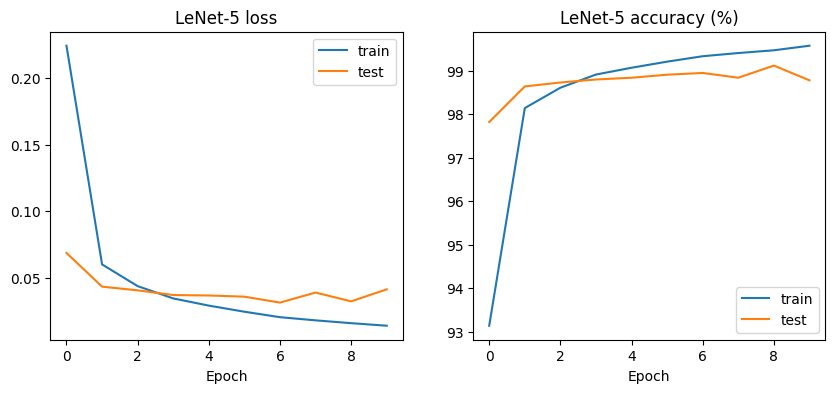

Train acc: 99.31666666666666  Test acc: 98.78


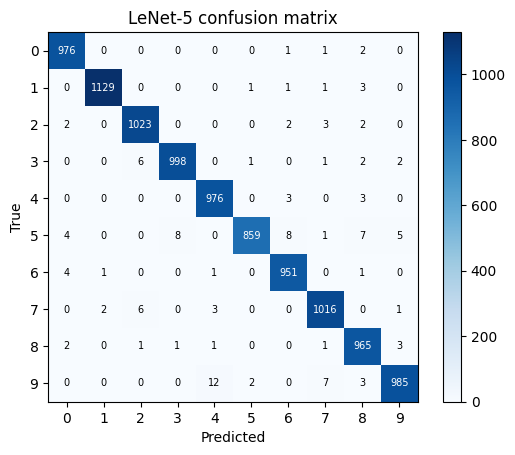

Epoch 1/10 | train loss 0.1414 acc 95.61% | test loss 0.0485 acc 98.40%
Epoch 2/10 | train loss 0.0580 acc 98.19% | test loss 0.0278 acc 99.06%
Epoch 3/10 | train loss 0.0440 acc 98.59% | test loss 0.0297 acc 99.06%
Epoch 4/10 | train loss 0.0347 acc 98.89% | test loss 0.0203 acc 99.31%
Epoch 5/10 | train loss 0.0320 acc 98.98% | test loss 0.0189 acc 99.35%
Epoch 6/10 | train loss 0.0272 acc 99.16% | test loss 0.0267 acc 99.13%
Epoch 7/10 | train loss 0.0227 acc 99.27% | test loss 0.0234 acc 99.20%
Epoch 8/10 | train loss 0.0225 acc 99.25% | test loss 0.0216 acc 99.34%
Epoch 9/10 | train loss 0.0199 acc 99.33% | test loss 0.0220 acc 99.23%
Epoch 10/10 | train loss 0.0171 acc 99.44% | test loss 0.0221 acc 99.35%


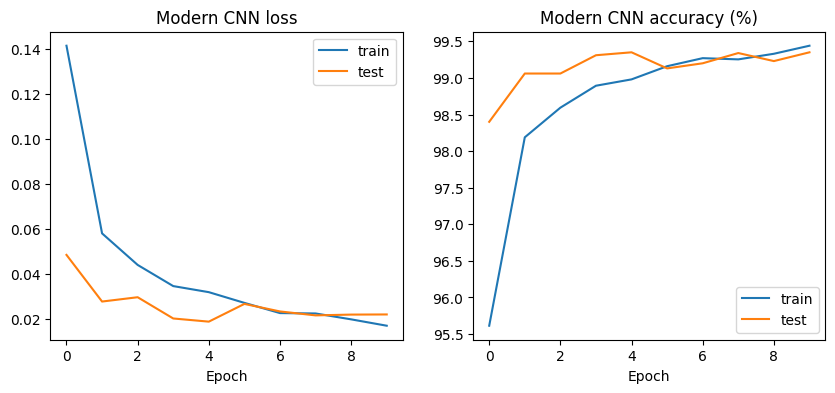

Train acc: 99.80333333333333  Test acc: 99.35


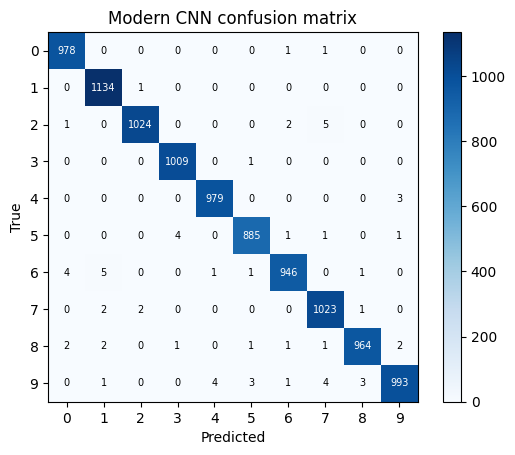

In [4]:
#running both models

hist_lenet = train_model(lenet)
plot_history(hist_lenet, 'LeNet-5')
print("Train acc:", evaluate(lenet, trainloader)[1], " Test acc:", evaluate(lenet, testloader)[1])
confusion_matrix(lenet, 'LeNet-5')

hist_cnn = train_model(cnn)
plot_history(hist_cnn, 'Modern CNN')
print("Train acc:", evaluate(cnn, trainloader)[1], " Test acc:", evaluate(cnn, testloader)[1])
confusion_matrix(cnn, 'Modern CNN')


### Discussion

Both models were trained on MNIST for 10 epochs under identical conditions (cross-entropy loss, Adam with learning rate 1e-3, batch size 64). (a) is LeNet-5 (about 62 k parameters). (b) is a small modern CNN (3 conv layers, each followed by batch normalisation, ReLU and max-pooling, then dropout 0.5 and a linear layer, about 105 k parameters).

| Model | Train acc (%) | Test acc (%) | Final test loss |
|---|---|---|---|
| LeNet-5 | 99.32 | 98.78 | 0.0412 |
| Modern CNN | 99.80 | 99.35 | 0.0221 |


**Training behaviour.** Both models converge quickly. After epoch 1 the CNN already reaches 98.40 % test accuracy and a train loss of 0.141, compared with 97.82 % and 0.225 for LeNet-5. The batch normalisation lets the CNN train faster from the start. In the first epochs the plotted training accuracy is lower than the test accuracy. This is because the training accuracy is a running average over the epoch while the weights are still improving, and for the CNN dropout is also active during training.

**Generalisation.** The CNN's test loss is low and stable, and its train and test curves stay close together. LeNet-5's test loss is noisier and drifts up in the last epochs, while its training loss keeps falling. so the final weights landed on a slightly worse step. This suggests the start of mild overfitting. The gap between train and test accuracy is small for both models, so neither is badly overfitted.

**Confusion matrices.** Both matrices are strongly diagonal. The CNN makes about 47 % fewer test errors (65 vs 122). LeNet-5's weakest class is digit 5, with 33 of 892 misclassified. The CNN cuts the errors for 5 to 7, and its remaining errors are spread more evenly. Its hardest class is 9, with 16 errors, mostly as 4 and 7, followed by 6 with 12 errors.

**Comparison.** The modern CNN is better on every measure: higher accuracy, lower loss, faster convergence and a more stable test curve. The improvements come from batch normalisation, dropout (regularisation) and a wider network with more feature channels.

## Question 03


### Discussion